# Thực nghiệm CNN trên UCI HAR

Notebook chính của đồ án tái hiện một phần Ronao & Cho (2016). Đầu vào 9 kênh là thiết kế của nhóm. Phiên bản này chuẩn bị dữ liệu và huấn luyện/đánh giá **validation**; chưa đánh giá test. Đọc `docs/research/protocol.md` trước khi chạy.

## 1. Chọn chế độ và thiết lập đường dẫn
`MODE="inspect"` chỉ đọc và xác minh dữ liệu/kết quả hiện có. Chọn `prepare` khi chưa có cache, `smoke` để chạy một epoch riêng, hoặc `official` để chạy ba seed. Không chạy lại chế độ chuẩn bị trong lúc huấn luyện. Mở notebook từ thư mục gốc hoặc `notebooks/`; ở máy khác cần chép cả mã nguồn và dữ liệu.

In [1]:
from pathlib import Path
import os, sys, json
MODE = "inspect"
assert MODE in {"inspect", "prepare", "smoke", "official"}
ROOT = Path.cwd().resolve()
if not (ROOT / "har_project").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "har_project").is_dir(), "Đặt ROOT tới thư mục chứa har_project"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
os.environ["MPLCONFIGDIR"] = str(ROOT / ".cache" / "matplotlib")
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
print("Project:", ROOT)
print("Python:", sys.executable)
print("Mode:", MODE)

Project: E:\PPNCKH\SGU26_PPNCKH_Group
Python: E:\PPNCKH\SGU26_PPNCKH_Group\.venv\Scripts\python.exe
Mode: inspect


## 2. Đọc, kiểm tra, chia tập và chuẩn hóa
Validation cố định gồm người 5, 11, 19, 26. Chỉ fit mean/std trên 5.982 mẫu fit-train. Test được chuẩn bị theo thống kê train nhưng không dùng để chọn mô hình hoặc tính điểm trong notebook này. Chế độ inspect xác minh SHA-256 và không ghi lại dữ liệu chuẩn bị.

In [2]:
from har_project.data import prepare, file_hash
summary_path = ROOT / "results/data_summary.json"
prepared_path = ROOT / "results/prepared/dataset.npz"
if MODE == "prepare":
    evidence = [summary_path, prepared_path, ROOT / "results/split.json", ROOT / "results/normalization.npz"]
    if any(p.exists() for p in evidence) or any((ROOT / "results/runs").glob("*/config.json")):
        raise FileExistsError("Đã có bằng chứng dữ liệu/run. Dùng inspect hoặc một thư mục output mới qua CLI.")
    summary = prepare(ROOT / "Dataset/UCI HAR Dataset", ROOT / "results")
else:
    if not summary_path.exists() or not prepared_path.exists():
        raise FileNotFoundError("Chưa có cache. Chạy MODE=prepare trước rồi chuyển về inspect.")
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    assert file_hash(prepared_path) == summary["prepared_sha256"], "Cache không khớp SHA-256"
    for relative, expected in summary["input_sha256"].items():
        assert file_hash(ROOT / "Dataset/UCI HAR Dataset" / relative) == expected, f"Dữ liệu nguồn thay đổi: {relative}"
for split in ("fit_train", "validation", "test"):
    print(split, summary[split]["shape"], summary[split]["subjects"])
print("Subject overlap:", summary["subject_overlap"])

fit_train [5982, 128, 9] [1, 3, 6, 7, 8, 14, 15, 16, 17, 21, 22, 23, 25, 27, 28, 29, 30]
validation [1370, 128, 9] [5, 11, 19, 26]
test [2947, 128, 9] [2, 4, 9, 10, 12, 13, 18, 20, 24]
Subject overlap: []


In [3]:
import pandas as pd
pd.DataFrame({split: summary[split]["class_counts"] for split in ("fit_train", "validation", "test")})

,fit_train,validation,test
WALKING,1000,226,496
WALKING_UPSTAIRS,877,196,471
WALKING_DOWNSTAIRS,804,182,420
SITTING,1038,248,491
STANDING,1124,250,532
LAYING,1139,268,537


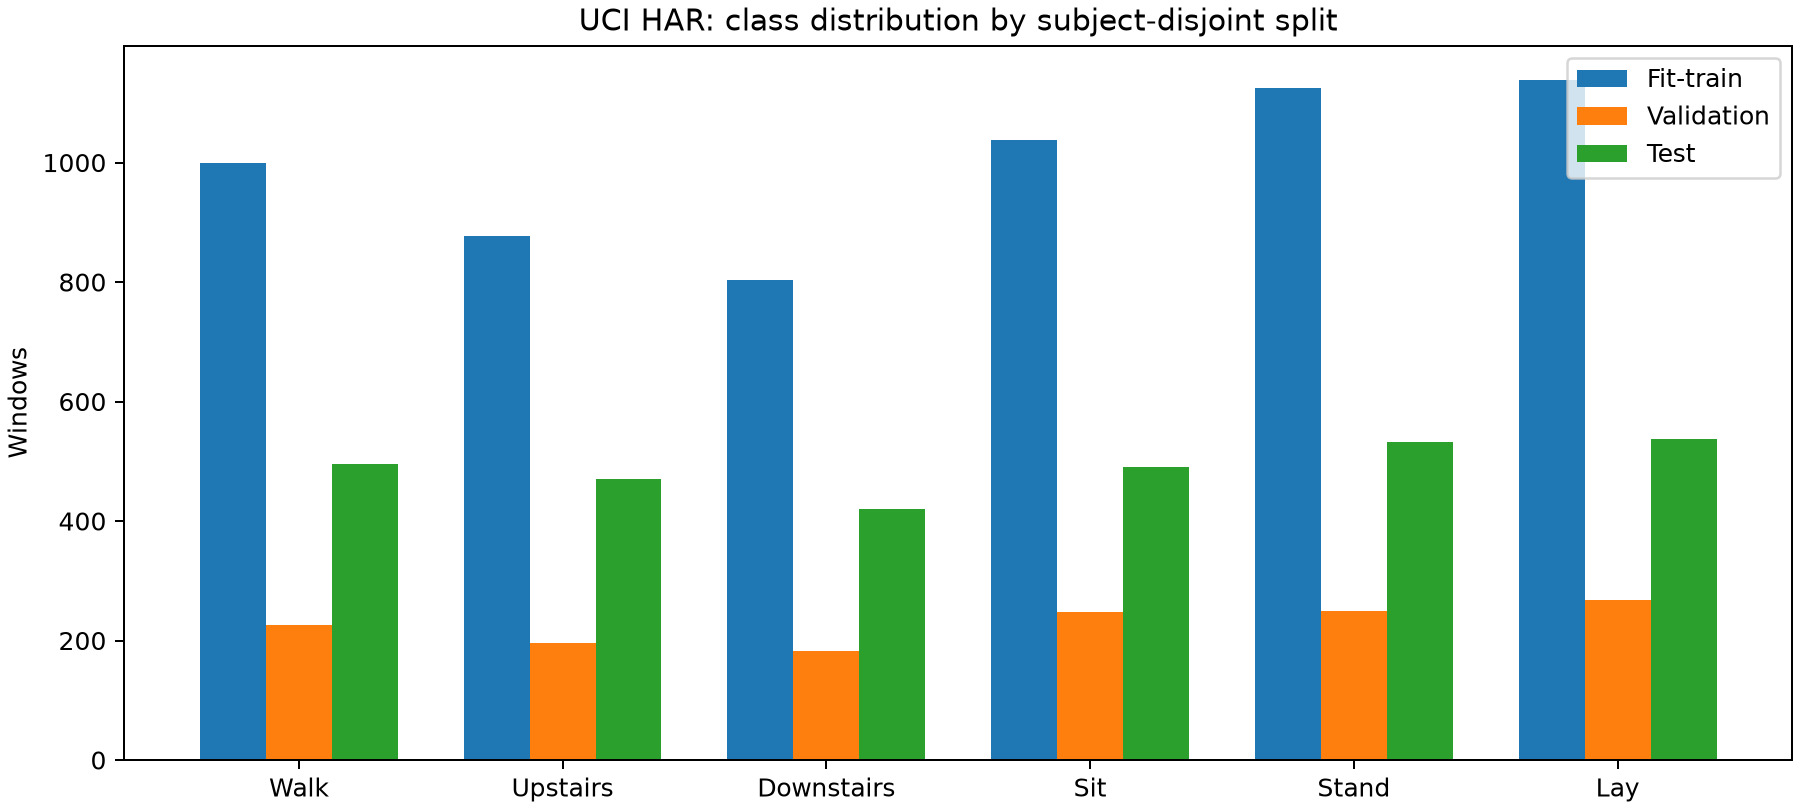

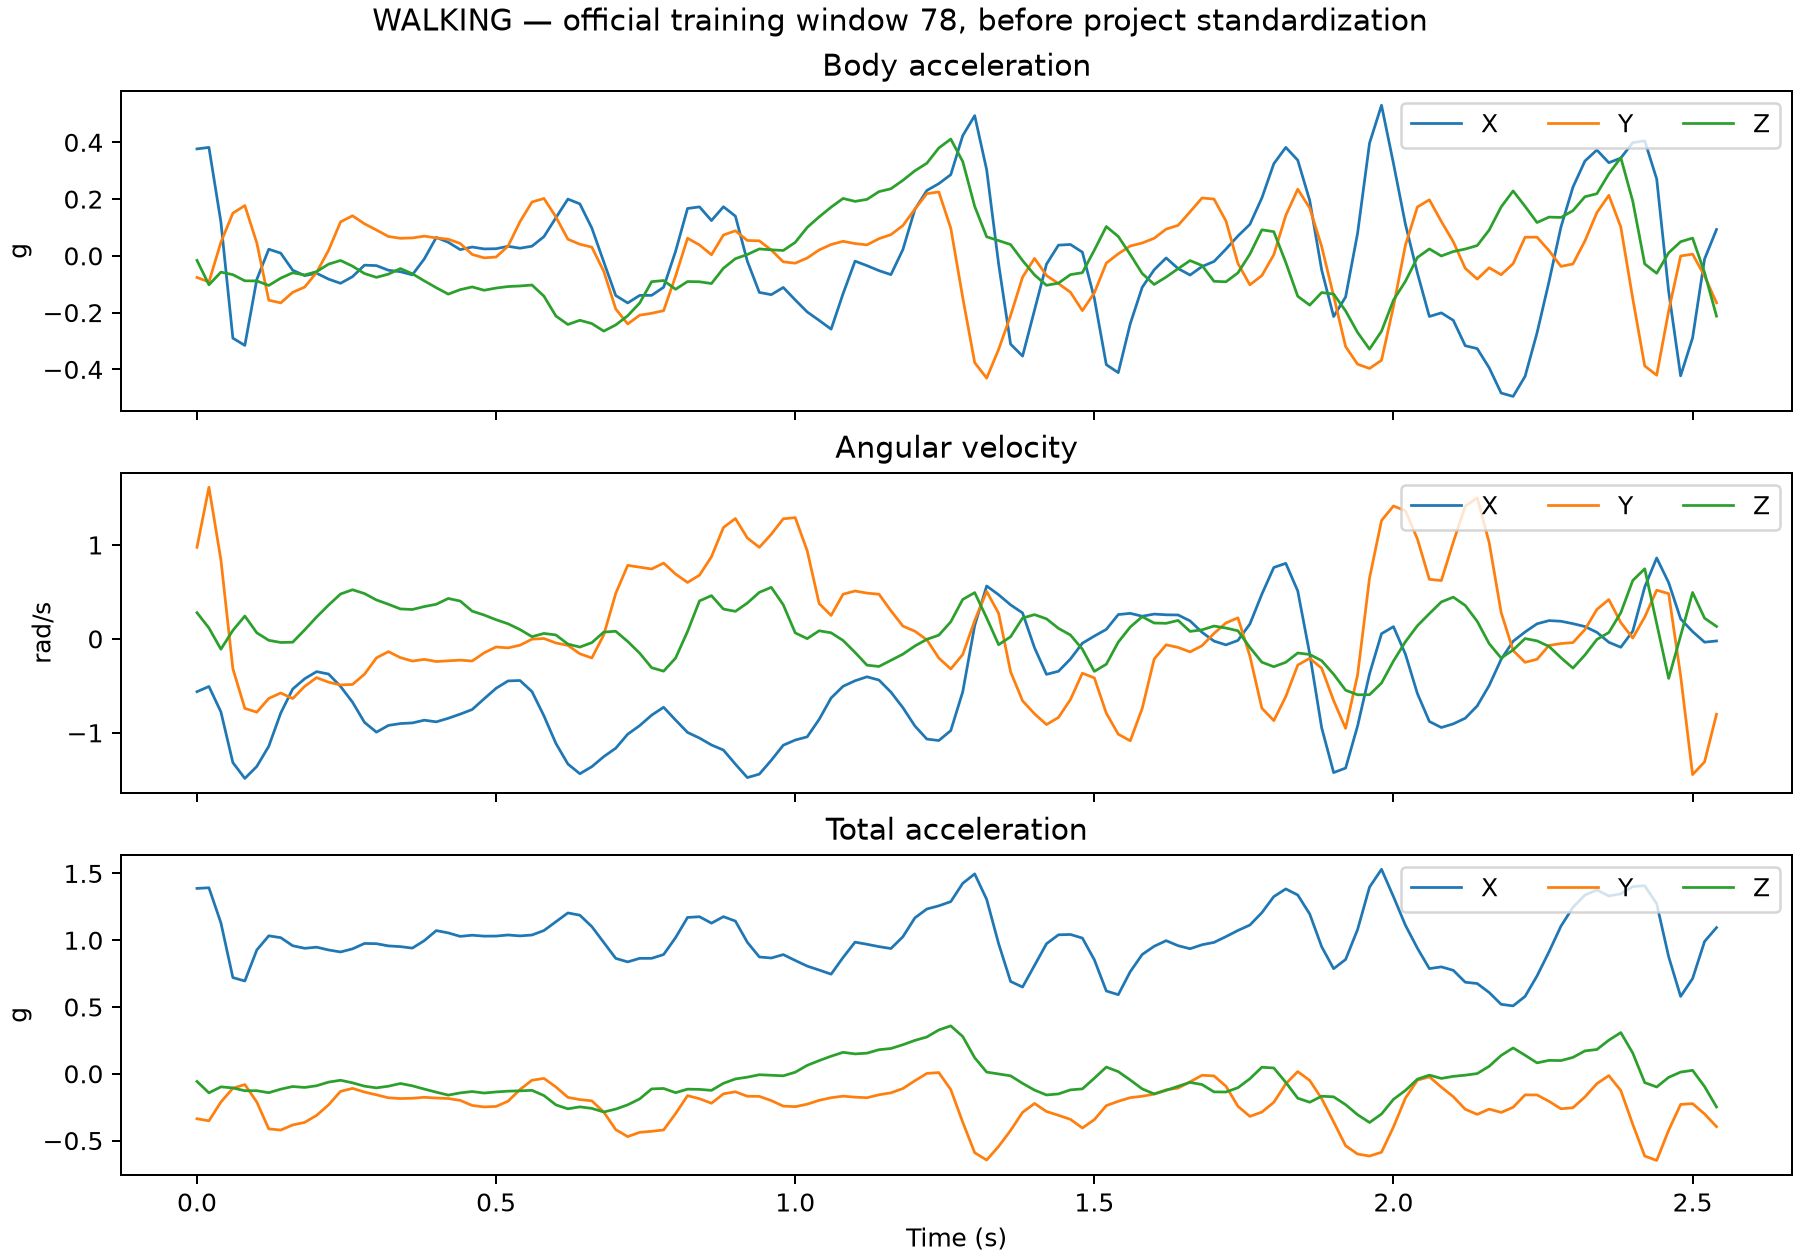

In [4]:
from IPython.display import display, Image
display(Image(filename="results/figures/class_distribution.png"))
display(Image(filename="results/figures/sample_signal_walking.png"))

## 3. Kiểm tra baseline trên validation
Lớp baseline được chọn từ fit-train; không chọn theo nhãn validation/test. Sáu nhãn đều tham gia tính Macro-F1.

In [5]:
import numpy as np
from har_project.experiment import baseline_validation
with np.load("results/prepared/dataset.npz") as data:
    baseline = baseline_validation(data["y_train"], data["y_validation"])
print(json.dumps({k: baseline[k] for k in ("split", "activity", "accuracy", "macro_f1")}, indent=2))

{
  "split": "validation",
  "activity": "LAYING",
  "accuracy": 0.19562043795620437,
  "macro_f1": 0.05453805453805454
}


## 4. Kiểm tra mô hình
CNN-B: Conv64/k5 → Pool2 → Conv128/k3 → GAP → Dense64 → Dropout0.3 → Softmax6. Seed được đặt lại trước mỗi lượt train.

In [6]:
from har_project.experiment import build_model, train_run
model = build_model("cnn_b")
model.summary()

Model: "cnn_b"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,294 (141.77 KB)

 Trainable params: 36,294 (141.77 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Chạy thử và huấn luyện chính thức
Chọn MODE ở phần 1. Các lượt đã có sẽ bị từ chối ghi đè. Muốn thực nghiệm lại, ghi rõ lý do trong protocol và dùng CLI với output phiên bản khác. Không chạy prepare đồng thời với tiến trình huấn luyện.

In [7]:
MODELS = ["cnn_b"]
SEEDS = [42, 123, 2026]
if MODE in {"smoke", "official"}:
    chosen_seeds = [42] if MODE == "smoke" else SEEDS
    for name in MODELS:
        for seed in chosen_seeds:
            folder = ROOT / "results" / ("smoke" if MODE == "smoke" else "runs") / f"{name}_seed{seed}"
            metrics = train_run(ROOT / "results/prepared/dataset.npz", folder, name, seed, smoke=MODE == "smoke")
            print(name, seed, metrics["macro_f1"])
else:
    print("Không khởi động huấn luyện mới trong chế độ này.")

Không khởi động huấn luyện mới trong chế độ này.


## 6. Đọc kết quả validation đã lưu
Các lượt smoke và official được ghi riêng. Bảng này không phải kết quả test; không dùng smoke để kết luận hiệu quả cuối.

In [8]:
records = []
for file in sorted((ROOT / "results").glob("*/cnn_*_seed*/validation_metrics.json")):
    row = json.loads(file.read_text(encoding="utf-8"))
    records.append({key: row[key] for key in ("kind", "model", "seed", "epochs_run", "best_epoch", "accuracy", "macro_f1", "training_seconds", "test_evaluated")})
pd.DataFrame(records)

,kind,model,seed,epochs_run,best_epoch,accuracy,macro_f1,training_seconds,test_evaluated
0,official,cnn_b,123,20,12,0.957664,0.959491,47.481765,False
1,official,cnn_b,2026,16,8,0.946715,0.950584,35.372130,False
2,official,cnn_b,42,10,2,0.946715,0.950433,22.560213,False
3,smoke,cnn_b,42,1,1,0.941606,0.944524,2.992303,False


## 7. Bước tiếp theo
Quyết định E2 và khóa protocol theo M5. Chỉ sau đó mới triển khai đánh giá test, confusion matrix cuối và bảng tổng hợp cho báo cáo. Mọi số liệu validation trong notebook phải được ghi đúng tên split.